<a href="https://colab.research.google.com/github/chamarairesh1982/ml-cybersecurity/blob/main/section3_anomaly/section3_anomaly.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Saved-run review and current protocol

Version 2 development revision: numeric scaling uses median centring with max(10/90 IQR, half training standard deviation), and scale 1 for constant columns. This prevents tiny IQRs from dominating reconstruction while preserving tail deviations. It is fitted independently inside each Normal-only CV boundary. The inspected publisher test is now opt-in historical replay (RUN_HISTORICAL_TEST=False); default Run all exports development evidence.

The historical findings and limitations are recorded in REPORT.md. The configuration and disjoint boundaries above govern this revision. Run in a fresh Colab runtime; independently measured improvement remains unverified.


# Section 3 — Network anomaly detection
**Independent learning lab • one self-contained Google Colab notebook**

Learn patterns from Normal-labelled reference traffic and ask whether unusual connections help identify corpus-labelled attacks. An anomaly is not automatically an attack. No Python script, local dataset, upload, Drive mount or credentials are required.

**Protocol:** provenance → audit/clean → grouped development partitions → Normal-only representation/model fitting → clustering and reconstruction → labelled development comparison → separate Normal-group alert calibration → freeze → optional inspected-benchmark replay → uncertainty and aggregate errors.

Fitting is one-class/novelty learning; choosing a winner with labelled validation is label-assisted benchmarking, not a completely label-free system. This historical benchmark cannot establish modern operational security. No real-data results are pre-filled.


## 1. Learning concepts and runtime
Apply preparation/EDA, feature scaling, clustering, dimensionality reduction, ensembles, neural reconstruction and imbalance-aware evaluation. MiniBatch K-means models Normal clusters; PCA/autoencoder reconstruction model Normal structure; Isolation Forest provides a different anomaly mechanism. DBSCAN is not forced into out-of-sample scoring without a principled prediction rule.

Classical models use CPU. The optional numerical autoencoder supports GPU/TPU strategies; string processing stays on CPU. Run all in a fresh Colab runtime. A common, declared Normal-reference cap limits fitting and optional LOF cost; it is part of this experiment, not an undisclosed sample reduction.

In [1]:
%pip -q install "requests>=2.31,<3"

In [2]:
import io, json, time, hashlib, platform, re, random
from pathlib import Path
import importlib.metadata as metadata
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import clone, BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, RobustScaler, FunctionTransformer
from sklearn.model_selection import StratifiedGroupKFold, GroupShuffleSplit
from sklearn.decomposition import PCA
from sklearn.cluster import MiniBatchKMeans
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_score,
    recall_score, f1_score, accuracy_score, confusion_matrix, silhouette_score,
    ConfusionMatrixDisplay, PrecisionRecallDisplay, RocCurveDisplay)
from scipy.stats import binom
from threadpoolctl import threadpool_limits

SEED=42
random.seed(SEED); np.random.seed(SEED)
RUN_NEURAL=True
RUN_LOF=False  # Optional: nearest-neighbour scoring can be expensive.
ACCELERATOR="auto"  # auto, cpu, gpu, tpu
CPU_THREADS=2
NORMAL_REFERENCE_CAP=12000
SCORE_BATCH=1024
EPOCHS=25
BOOTSTRAPS=200
TARGET_GROUP_FPR=.01
POLICY_CONFIDENCE=.95
REVISION="9d544d0eb9b87d7e2f43ff65733bdb644631d12f"
BASE_URL=f"https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/{REVISION}"
FILES={
    "train":("KDDTrain%2B.txt","20002897492adc110190a10509aa694f26f7f308",19109424),
    "test":("KDDTest%2B.txt","b30e89605285a5ccd8cf8fd38dba72906c20d3dd",3441513)}
FEATURES=["duration","protocol_type","service","flag","src_bytes","dst_bytes","land",
    "wrong_fragment","urgent","hot","num_failed_logins","logged_in","num_compromised",
    "root_shell","su_attempted","num_root","num_file_creations","num_shells",
    "num_access_files","num_outbound_cmds","is_host_login","is_guest_login","count",
    "srv_count","serror_rate","srv_serror_rate","rerror_rate","srv_rerror_rate",
    "same_srv_rate","diff_srv_rate","srv_diff_host_rate","dst_host_count",
    "dst_host_srv_count","dst_host_same_srv_rate","dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate","dst_host_srv_diff_host_rate","dst_host_serror_rate",
    "dst_host_srv_serror_rate","dst_host_rerror_rate","dst_host_srv_rerror_rate"]
CATEGORICAL=["protocol_type","service","flag"]
NUMERIC=[c for c in FEATURES if c not in CATEGORICAL]
COLUMNS=FEATURES+["attack_name","difficulty"]
versions={p:metadata.version(p) for p in
          ["numpy","pandas","scikit-learn","matplotlib","scipy","requests"]}
print("Python:",platform.python_version(),"packages:",versions)
print("Normal reference cap:",NORMAL_REFERENCE_CAP,"optional LOF:",RUN_LOF)
RUN_HISTORICAL_TEST = False  # Inspected saved benchmark; opt-in replay only.
EXPERIMENT_VERSION = "section3-v2-development"


Python: 3.13.15 packages: {'numpy': '2.1.3', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'scipy': '1.16.3', 'requests': '2.32.4'}
Normal reference cap: 12000 optional LOF: False


## 2. Data provenance and identity
Use NSL-KDD, attributed to M. Tavallaee, E. Bagheri, W. Lu and A. Ghorbani, *A Detailed Analysis of the KDD CUP 99 Data Set*, CISDA 2009. The [original provider](https://www.unb.ca/cic/datasets/nsl.html) permits use/redistribution with dataset/paper citation but no longer hosts the download. This notebook uses a [third-party archival mirror](https://github.com/jmnwong/NSL-KDD-Dataset/tree/9d544d0eb9b87d7e2f43ff65733bdb644631d12f), pinned by commit, Git blob object ID and byte count. This verifies mirror identity, not independent ground-truth correctness. Git SHA-1 identity is not a modern adversarial security guarantee; a runtime SHA-256 is recorded for evidence.

The CSV contains 41 predictors, an attack name and a difficulty field. Exclude the label and difficulty from predictors. Host/service history and content counters are offline benchmark measurements, not guaranteed available before a live decision. Missing verified session/timestamps prevents a chronological/source claim. The publisher-selected population and label-dependent cleaning differ from deployment prevalence. Fetch only training now; test is deferred until choices freeze.

In [3]:
def parse_payload(payload):
    frame=pd.read_csv(io.BytesIO(payload),header=None)
    if frame.shape[1]!=len(COLUMNS):
        raise ValueError(f"Expected {len(COLUMNS)} fields, found {frame.shape[1]}. Do not guess schema.")
    frame.columns=COLUMNS
    return frame

def load_partition(name):
    path,expected_blob,expected_size=FILES[name]
    response=requests.get(f"{BASE_URL}/{path}",timeout=(20,180))
    response.raise_for_status()
    payload=response.content
    blob=hashlib.sha1(f"blob {len(payload)}\0".encode()+payload).hexdigest()
    if len(payload)!=expected_size or blob!=expected_blob:
        raise ValueError("Mirror identity mismatch; investigate before changing the pin.")
    return parse_payload(payload),{"bytes":len(payload),"git_blob":blob,
        "sha256":hashlib.sha256(payload).hexdigest()}

raw_train,download_train=load_partition("train")
print("Training loaded into Colab memory:",download_train)

Training loaded into Colab memory: {'bytes': 19109424, 'git_blob': '20002897492adc110190a10509aa694f26f7f308', 'sha256': '1b86d2f957b33082081bba410fe129b475efebcc13c9014c3f447c8271aadf95'}


## 3. Audit and conservative cleaning
Inspect schema, missingness, numeric validity and provider labels without printing flows. Missing labels are excluded; negative/nonfinite/nonnumeric numeric values become missing and are counted. Categorical strings are normalized. Remove all feature-identical contradictory binary labels, then consistent duplicates, using feature hashes as a practical proxy; hash collisions remain possible.

Report per-label retention. Deduplication can remove attack-frequency information and change the population. Binary-consistent duplicates retain the first attack-name representative; groups with multiple names are audited, and name-level metrics inherit that ambiguity. Do not treat removed contradictory rows as solved label noise.

In [4]:
def clean_partition(frame):
    if list(frame.columns)!=COLUMNS:
        raise ValueError("Unexpected schema/order.")
    audit={"input_rows":len(frame)}
    work=frame.copy()
    labels=work["attack_name"].astype("string").str.strip().str.lower().str.rstrip(".")
    missing=labels.isna()|labels.eq("")
    audit["missing_label_rows_removed"]=int(missing.sum())
    work=work.loc[~missing].copy(); labels=labels.loc[~missing]
    if not labels.str.fullmatch(r"[a-z][a-z0-9_]*").all():
        raise ValueError("Malformed labels; investigate provider data.")
    work["attack_name"]=labels
    work["target"]=(labels!="normal").astype("int32")
    invalid_counts={}
    for column in NUMERIC:
        original=work[column]
        values=pd.to_numeric(original,errors="coerce").astype("float64")
        invalid=~np.isfinite(values)|(values<0)
        invalid_counts[column]=int((invalid&original.notna()).sum())
        work[column]=values.mask(invalid,np.nan)
    for column in CATEGORICAL:
        v=work[column].astype("string").str.strip().str.lower()
        work[column]=v.mask(v.eq(""),pd.NA).astype(object)
        work[column]=work[column].where(pd.notna(work[column]),np.nan)
    work["feature_hash"]=pd.util.hash_pandas_object(work[FEATURES],index=False).astype("uint64")
    clashes=work.groupby("feature_hash")["target"].nunique()
    bad=work["feature_hash"].isin(clashes[clashes>1].index)
    audit["contradictory_feature_rows_removed"]=int(bad.sum())
    work=work.loc[~bad].copy()
    audit["feature_groups_with_multiple_attack_names"]=int((work.groupby("feature_hash")["attack_name"].nunique()>1).sum())
    audit["consistent_duplicate_rows_removed"]=int(work["feature_hash"].duplicated().sum())
    work=work.drop_duplicates("feature_hash").reset_index(drop=True)
    before=labels.value_counts();after=work["attack_name"].value_counts()
    audit["label_retention"]={name:{"input_rows":int(before[name]),
        "retained_rows":int(after.get(name,0))} for name in before.index}
    audit["invalid_numeric_values_to_missing"]=invalid_counts
    audit["retained_rows"]=len(work)
    return work[FEATURES+["attack_name","target","feature_hash"]],audit

display(pd.DataFrame({"dtype":raw_train.dtypes.astype(str),"missing":raw_train.isna().sum()}))
display(raw_train["attack_name"].value_counts(dropna=False).rename("provider_support").to_frame())
pool,cleaning_train=clean_partition(raw_train)
del raw_train
display(pd.Series({k:v for k,v in cleaning_train.items() if isinstance(v,int)}).to_frame("count"))
display(pd.DataFrame.from_dict(cleaning_train["label_retention"],orient="index"))

,dtype,missing
duration,int64,0
protocol_type,object,0
service,object,0
flag,object,0
src_bytes,int64,0
dst_bytes,int64,0
land,int64,0
wrong_fragment,int64,0
urgent,int64,0
hot,int64,0


,provider_support
attack_name,
normal,67343
neptune,41214
satan,3633
ipsweep,3599
portsweep,2931
smurf,2646
nmap,1493
back,956
teardrop,892


,count
input_rows,125973
missing_label_rows_removed,0
contradictory_feature_rows_removed,14
feature_groups_with_multiple_attack_names,8
consistent_duplicate_rows_removed,9
retained_rows,125950


,input_rows,retained_rows
normal,67343,67336
neptune,41214,41214
satan,3633,3632
ipsweep,3599,3593
portsweep,2931,2930
smurf,2646,2646
nmap,1493,1491
back,956,956
teardrop,892,892
warezclient,890,890


## 4. Group related features and freeze development partitions
Group all model-input categorical fields plus numeric values rounded to four significant digits. These approximate groups reduce exact/rounded related-feature leakage but are not session IDs. Use five fixed stratified group folds: three for Normal-reference development, one mixed labelled selection fold and one separate policy fold. Do not search for lucky seeds.

Split Normal reference-development groups again into fitting and Normal-only stopping data. Sample complete fitting groups deterministically up to the declared cap, without labels beyond the trusted Normal eligibility. Every detector uses the same capped reference. Do not estimate contamination from test labels.

In [5]:
def rounded_groups(frame):
    rounded=frame[FEATURES].copy()
    for column in NUMERIC:
        values=rounded[column].to_numpy(dtype="float64")
        nz=np.isfinite(values)&(values!=0)
        scale=np.ones_like(values)
        scale[nz]=np.power(10.,np.clip(3-np.floor(np.log10(np.abs(values[nz]))),-300,300))
        rounded[column]=np.round(values*scale)/scale
    return pd.util.hash_pandas_object(rounded,index=False).to_numpy(dtype="uint64")

pool["group"]=rounded_groups(pool)
if pool["target"].nunique()!=2 or pool.groupby("target")["group"].nunique().min()<10:
    raise ValueError("Need both labels and sufficient related-feature groups.")
splitter=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED)
folds=[held for _,held in splitter.split(pool,pool["target"],pool["group"])]
reference_pool=pool.iloc[np.concatenate(folds[:3])].reset_index(drop=True)
selection=pool.iloc[folds[3]].reset_index(drop=True)
policy=pool.iloc[folds[4]].reset_index(drop=True)
normal_pool=reference_pool.loc[reference_pool["target"]==0].reset_index(drop=True)
fit_idx,stop_idx=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED).split(
    normal_pool,groups=normal_pool["group"]))
uncapped=normal_pool.iloc[fit_idx].reset_index(drop=True)
normal_stop=normal_pool.iloc[stop_idx].reset_index(drop=True)
def cap_reference(frame,cap):
    if cap<2:
        raise ValueError("Reference cap too small.")
    sizes=frame["group"].value_counts()
    rng=np.random.default_rng(SEED)
    chosen=[];used=0
    for group in rng.permutation(sizes.index.to_numpy()):
        count=int(sizes[group])
        if used+count<=cap:
            chosen.append(group);used+=count
    result=frame.loc[frame["group"].isin(chosen)].reset_index(drop=True)
    if len(result)<min(100,cap):
        raise ValueError("Whole-group cap retained too few Normal rows.")
    return result
normal_fit=cap_reference(uncapped,NORMAL_REFERENCE_CAP)
parts={"normal_fit":normal_fit,"normal_stop":normal_stop,"selection":selection,"policy":policy}
for name,frame in parts.items():
    if len(frame)<2:
        raise ValueError(f"Too few rows: {name}")
    if name in {"selection","policy"} and frame["target"].nunique()!=2:
        raise ValueError(f"{name} lacks a label; inspect grouping rather than retrying seeds.")
for i,a in enumerate(parts):
    for b in list(parts)[i+1:]:
        assert not set(parts[a]["group"]) & set(parts[b]["group"])
        assert not set(parts[a]["feature_hash"]) & set(parts[b]["feature_hash"])
assert normal_fit["target"].eq(0).all() and normal_stop["target"].eq(0).all()
development_attack_names=set(pool.loc[pool["target"]==1,"attack_name"])
display(pd.DataFrame([{"partition":name,"rows":len(frame),"groups":frame["group"].nunique(),
    "attack_fraction":frame["target"].mean()} for name,frame in parts.items()]))
print("Normal fitting rows before cap:",len(uncapped),"after:",len(normal_fit))
print("Excluded reference-pool attacks:",int(reference_pool["target"].sum()))

,partition,rows,groups,attack_fraction
0,normal_fit,12000,12000,0.000000
1,normal_stop,8084,8084,0.000000
2,selection,25191,25190,0.466595
3,policy,25190,25190,0.464946


Normal fitting rows before cap: 32337 after: 12000
Excluded reference-pool attacks: 35148


## 5. Normal-only EDA and representation
Plot Normal-reference distributions, not test data. Median imputation, log1p numerical transformation, guarded robust scaling and infrequent-category encoding fit only on the selected Normal reference. The log transform reduces count tails; the numerical scale is max(10/90 interquantile range, half standard deviation), or 1 for constants, fitted only on the Normal reference. This prevents tiny ranges from arbitrarily amplifying residuals while keeping tail deviations. It does not prove resistance to contamination. One-hot columns remain unscaled.

Append one unseen-category flag per categorical field using Normal-reference known values. These flags are zero during fitting; reconstruction/distance models can respond when a new category appears, while a tree cannot split a constant training flag. Features with zero Normal variation otherwise remain an acknowledged limitation. Labels/difficulty never enter matrices.


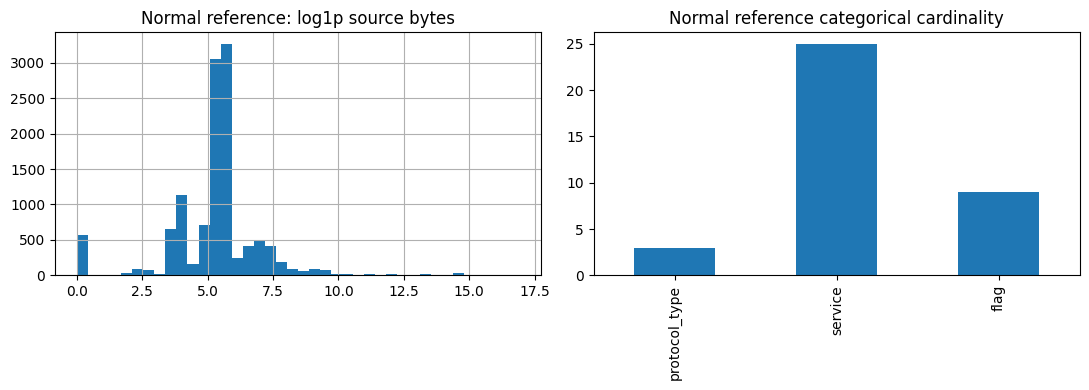

Reference matrix shape: (12000, 70) MB: 3.36
Near-constant Normal columns: 7
Numeric scale-floor columns: 22


In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
np.log1p(normal_fit["src_bytes"]).hist(bins=40,ax=axes[0])
axes[0].set_title("Normal reference: log1p source bytes")
normal_fit[CATEGORICAL].nunique().plot.bar(ax=axes[1])
axes[1].set_title("Normal reference categorical cardinality")
plt.tight_layout();plt.show()

class GuardedRobustScaler(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        values = np.asarray(X, dtype="float64")
        self.center_ = np.median(values, axis=0)
        iqr = np.quantile(values, .9, axis=0) - np.quantile(values, .1, axis=0)
        spread = np.std(values, axis=0)
        self.scale_ = np.where(spread < 1e-8, 1., np.maximum(iqr, .5 * spread))
        self.guarded_columns_ = int(np.sum(iqr < .5 * spread))
        return self
    def transform(self, X):
        result = (np.asarray(X, dtype="float64") - self.center_) / self.scale_
        if not np.isfinite(result).all():
            raise ValueError("Nonfinite scaled representation")
        return result.astype("float32")

def log_numeric(values):
    return np.log1p(values).astype("float32")
encoder=ColumnTransformer([
    ("numeric",Pipeline([
        ("impute",SimpleImputer(strategy="median",keep_empty_features=True)),
        ("log",FunctionTransformer(log_numeric,feature_names_out="one-to-one")),
        ("scale",GuardedRobustScaler())]),NUMERIC),
    ("categorical",Pipeline([
        ("impute",SimpleImputer(strategy="constant",fill_value="missing")),
        ("encode",OneHotEncoder(handle_unknown="infrequent_if_exist",min_frequency=10,
                               sparse_output=False,dtype=np.float32))]),CATEGORICAL)])
known_categories={column:set(normal_fit[column].dropna()) for column in CATEGORICAL}
encoder.fit(normal_fit[FEATURES])
def encode_frame(frame):
    base=encoder.transform(frame[FEATURES]).astype("float32")
    unseen=np.column_stack([(~frame[c].isin(known_categories[c])).to_numpy(dtype="float32")
                            for c in CATEGORICAL])
    matrix=np.column_stack([base,unseen]).astype("float32")
    if not np.isfinite(matrix).all():
        raise ValueError("Nonfinite encoded values; inspect extreme inputs.")
    return matrix
fit_matrix=encode_frame(normal_fit)
stop_matrix=encode_frame(normal_stop)
assert fit_matrix.shape[1]==stop_matrix.shape[1]
print("Reference matrix shape:",fit_matrix.shape,"MB:",fit_matrix.nbytes/1e6)
print("Near-constant Normal columns:",int((fit_matrix.std(axis=0)<1e-8).sum()))
print("Numeric scale-floor columns:", encoder.named_transformers_["numeric"]["scale"].guarded_columns_)


## 6. Fit declared anomaly candidates
All scores point upward toward greater anomaly. Ignore estimators' built-in contamination thresholds; the independent policy stage sets alerts. No attack rows or attack names train these detectors.

Compare a simple squared robust-distance baseline, PCA reconstruction at two variance-retention settings, nearest-cluster distance at two cluster counts, and Isolation Forest at two subsample sizes. Optional LOF uses `novelty=True` and scores only unseen partitions, never its own fitting rows. Record fitting and scoring time. The common reference cap and batched scoring bound memory, not total computation. [Novelty detection guidance](https://scikit-learn.org/stable/modules/outlier_detection.html).

Tune the classical setting pairs using three grouped training-only folds. Each fold fits fresh Normal-only encoding and detectors; held-out training-fold labels provide benchmark AP. Maximise mean AP minus fold standard deviation, a declared stability heuristic. Normal stopping, mixed selection, policy and publisher test rows never enter these CV folds. This tuning is label-assisted too. Fit the chosen setting per family on the same final Normal reference, then compare families on the separate selection partition.

In [7]:
# Training-only grouped CV chooses classical settings before mixed model selection.
# Clone the encoder: discard its fitted reference state inside every CV fold.
eligible=reference_pool.loc[~reference_pool["group"].isin(normal_stop["group"])].reset_index(drop=True)
cv_splitter=StratifiedGroupKFold(n_splits=3,shuffle=True,random_state=SEED+1)
cv_specs=[("pca",.80),("pca",.95),("kmeans",8),("kmeans",32),
          ("isolation",256),("isolation",1024)]
cv_records=[]
with threadpool_limits(limits=CPU_THREADS):
    for fold,(train_idx,held_idx) in enumerate(cv_splitter.split(
            eligible,eligible["target"],eligible["group"])):
        fold_train=eligible.iloc[train_idx]
        held=eligible.iloc[held_idx]
        assert not set(fold_train["group"]) & set(held["group"])
        fold_normal=cap_reference(fold_train.loc[fold_train["target"]==0].reset_index(drop=True),
                                  NORMAL_REFERENCE_CAP)
        if held["target"].nunique()!=2:
            raise ValueError("A training CV holdout lacks a label; do not hunt lucky splits.")
        fold_encoder=clone(encoder).fit(fold_normal[FEATURES])
        fold_known={column:set(fold_normal[column].dropna()) for column in CATEGORICAL}
        def fold_encode(frame):
            base=fold_encoder.transform(frame[FEATURES]).astype("float32")
            flags=np.column_stack([(~frame[c].isin(fold_known[c])).to_numpy(dtype="float32")
                                   for c in CATEGORICAL])
            matrix=np.column_stack([base,flags]).astype("float32")
            if not np.isfinite(matrix).all():
                raise ValueError("Nonfinite fold representation.")
            return matrix
        xx,hh=fold_encode(fold_normal),fold_encode(held)
        for kind,setting in cv_specs:
            started=time.perf_counter()
            if kind=="pca":
                model=PCA(n_components=setting,svd_solver="full").fit(xx)
            elif kind=="kmeans":
                model=MiniBatchKMeans(n_clusters=setting,batch_size=1024,n_init=3,random_state=SEED).fit(xx)
            else:
                model=IsolationForest(n_estimators=200,max_samples=min(setting,len(xx)),
                    contamination="auto",random_state=SEED,n_jobs=CPU_THREADS).fit(xx)
            batches=[]
            for i in range(0,len(hh),SCORE_BATCH):
                batch=hh[i:i+SCORE_BATCH]
                if kind=="pca":
                    ss=np.mean((batch.astype("float64")-model.inverse_transform(model.transform(batch)))**2,axis=1)
                elif kind=="kmeans":
                    ss=np.min(model.transform(batch),axis=1)
                else:
                    ss=-model.score_samples(batch)
                batches.append(ss)
            scores=np.concatenate(batches)
            if not np.isfinite(scores).all():
                raise ValueError("Nonfinite training CV scores.")
            cv_records.append({"family":kind,"setting":setting,"fold":fold,
                "heldout_AP":average_precision_score(held["target"],scores),
                "reference_rows":len(xx),"fit_and_score_seconds":time.perf_counter()-started})
cv_folds_table=pd.DataFrame(cv_records)
cv_table=cv_folds_table.groupby(["family","setting"],as_index=False).agg(
    CV_AP=("heldout_AP","mean"),CV_std=("heldout_AP","std"),
    CV_seconds=("fit_and_score_seconds","sum"))
cv_table["stability_utility"]=cv_table["CV_AP"]-cv_table["CV_std"]
cv_choices={}
for family,rows in cv_table.groupby("family"):
    chosen=rows.sort_values(["stability_utility","CV_seconds"],ascending=[False,True]).iloc[0]
    cv_choices[family]=float(chosen["setting"]) if family=="pca" else int(chosen["setting"])
display(cv_table)
print("Frozen training-CV classical settings:",cv_choices)

,family,setting,CV_AP,CV_std,CV_seconds,stability_utility
0,isolation,256.00,0.983391,0.001238,3.131708,0.982153
1,isolation,1024.00,0.987915,0.001373,3.675272,0.986542
2,kmeans,8.00,0.945770,0.004413,0.350288,0.941357
3,kmeans,32.00,0.952858,0.000667,0.579742,0.952190
4,pca,0.80,0.923527,0.001596,0.930674,0.921930
5,pca,0.95,0.882777,0.016717,0.727099,0.866060


Frozen training-CV classical settings: {'isolation': 1024, 'kmeans': 32, 'pca': 0.8}


In [8]:
detectors={};fit_seconds={};score_seconds={}
started=time.perf_counter()
center=np.median(fit_matrix,axis=0)
detectors["robust_distance"]=("distance",center)
fit_seconds["robust_distance"]=time.perf_counter()-started
with threadpool_limits(limits=CPU_THREADS):
    for retained in [cv_choices["pca"]]:
        name=f"pca_{retained}"
        start=time.perf_counter()
        model=PCA(n_components=retained,svd_solver="full").fit(fit_matrix)
        detectors[name]=("pca",model);fit_seconds[name]=time.perf_counter()-start
        print(name,"components:",model.n_components_,"fit seconds:",fit_seconds[name])
    for clusters in [cv_choices["kmeans"]]:
        if len(fit_matrix)<clusters:
            raise ValueError("Too few reference rows for declared clusters.")
        name=f"kmeans_{clusters}";start=time.perf_counter()
        model=MiniBatchKMeans(n_clusters=clusters,batch_size=1024,n_init=3,
                             random_state=SEED).fit(fit_matrix)
        detectors[name]=("kmeans",model);fit_seconds[name]=time.perf_counter()-start
    for samples in [cv_choices["isolation"]]:
        name=f"isolation_{samples}";start=time.perf_counter()
        model=IsolationForest(n_estimators=200,max_samples=min(samples,len(fit_matrix)),
                              contamination="auto",random_state=SEED,n_jobs=CPU_THREADS).fit(fit_matrix)
        detectors[name]=("isolation",model);fit_seconds[name]=time.perf_counter()-start
    if RUN_LOF:
        start=time.perf_counter()
        model=LocalOutlierFactor(n_neighbors=35,novelty=True,n_jobs=CPU_THREADS).fit(fit_matrix)
        detectors["lof"]=("lof",model);fit_seconds["lof"]=time.perf_counter()-start

def score_detector(name,matrix):
    kind,model=detectors[name]
    if kind=="autoencoder":
        # One batched predict call avoids rebuilding tf.data for every scoring chunk.
        reconstruction=model.predict(numeric_dataset(matrix),verbose=0)
        result=np.mean((matrix.astype("float64")-reconstruction)**2,axis=1)
        if result.shape!=(len(matrix),) or not np.isfinite(result).all():
            raise ValueError("Invalid autoencoder scores")
        return result
    values=[]
    with threadpool_limits(limits=CPU_THREADS):
        for i in range(0,len(matrix),SCORE_BATCH):
            batch=matrix[i:i+SCORE_BATCH]
            if kind=="distance":
                score=np.mean((batch.astype("float64")-model)**2,axis=1)
            elif kind=="pca":
                reconstruction=model.inverse_transform(model.transform(batch))
                score=np.mean((batch.astype("float64")-reconstruction)**2,axis=1)
            elif kind=="kmeans":
                score=np.min(model.transform(batch),axis=1)
            elif kind in {"isolation","lof"}:
                score=-model.score_samples(batch)
            elif kind=="autoencoder":
                reconstruction=model.predict(numeric_dataset(batch),verbose=0)
                score=np.mean((batch.astype("float64")-reconstruction)**2,axis=1)
            elif kind=="rank_ensemble":
                scores=[score_detector(member,batch) for member in model]
                score=np.mean([np.searchsorted(rank_references[member],ss,side="right")/
                    (len(rank_references[member])+1) for member,ss in zip(model,scores)],axis=0)
            else:
                raise ValueError("Unknown detector kind.")
            values.append(np.asarray(score,dtype="float64"))
    result=np.concatenate(values)
    if result.shape!=(len(matrix),) or not np.isfinite(result).all():
        raise ValueError(f"Invalid anomaly scores: {name}")
    return result

# Fixed rank-average ensemble, with score scales learned only from Normal stopping data.
members=[f"pca_{cv_choices['pca']}",f"kmeans_{cv_choices['kmeans']}",
         f"isolation_{cv_choices['isolation']}"]
rank_references={name:np.sort(score_detector(name,stop_matrix)) for name in members}
detectors["rank_ensemble"]=("rank_ensemble",members)
fit_seconds["rank_ensemble"]=sum(fit_seconds[name] for name in members)
rng=np.random.default_rng(SEED)
sample=rng.choice(len(fit_matrix),size=min(1500,len(fit_matrix)),replace=False)
cluster_model=detectors[f"kmeans_{cv_choices['kmeans']}"][1]
cluster_labels=cluster_model.predict(fit_matrix[sample])
if 1<len(np.unique(cluster_labels))<len(sample):
    print("Normal-only sampled silhouette:",silhouette_score(fit_matrix[sample],cluster_labels))
print("Silhouette describes geometry, not attack detection quality.")


pca_0.8 components: 10 fit seconds: 0.04547227500000872
Normal-only sampled silhouette: 0.23396999
Silhouette describes geometry, not attack detection quality.


## 7. Optional neural reconstruction comparator
Train a bottleneck autoencoder on the same numerical Normal reference with Normal-only early stopping. Use two fixed seeds and Huber training loss to reduce sensitivity to large reconstruction residuals. The declared anomaly score remains mean squared reconstruction error, reported honestly even though the training loss differs.

No attack labels tune epochs. Output is linear because robust-scaled values are unbounded. Do not fit preprocessing to validation or test. GPU/TPU execution of this notebook still needs verification in Colab; a CPU smoke test is not accelerator validation.

Strategy: MirroredStrategy replicas: 1
Epoch 1/25
94/94 - 4s - 37ms/step - loss: 0.1122 - val_loss: 0.0823
Epoch 2/25
94/94 - 1s - 10ms/step - loss: 0.0724 - val_loss: 0.0622
Epoch 3/25
94/94 - 2s - 18ms/step - loss: 0.0591 - val_loss: 0.0506
Epoch 4/25
94/94 - 1s - 14ms/step - loss: 0.0480 - val_loss: 0.0377
Epoch 5/25
94/94 - 2s - 23ms/step - loss: 0.0384 - val_loss: 0.0338
Epoch 6/25
94/94 - 1s - 10ms/step - loss: 0.0354 - val_loss: 0.0316
Epoch 7/25
94/94 - 1s - 10ms/step - loss: 0.0336 - val_loss: 0.0297
Epoch 8/25
94/94 - 1s - 10ms/step - loss: 0.0317 - val_loss: 0.0280
Epoch 9/25
94/94 - 1s - 10ms/step - loss: 0.0297 - val_loss: 0.0253
Epoch 10/25
94/94 - 1s - 10ms/step - loss: 0.0271 - val_loss: 0.0240
Epoch 11/25
94/94 - 1s - 10ms/step - loss: 0.0259 - val_loss: 0.0230
Epoch 12/25
94/94 - 1s - 10ms/step - loss: 0.0253 - val_loss: 0.0227
Epoch 13/25
94/94 - 1s - 10ms/step - loss: 0.0246 - val_loss: 0.0220
Epoch 14/25
94/94 - 1s - 10ms/step - loss: 0.0240 - val_loss: 0.0214
Epoc

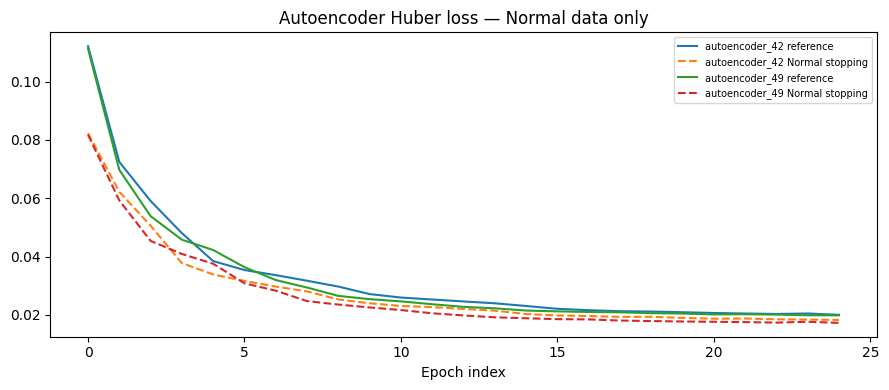

In [9]:
if RUN_NEURAL:
    import tensorflow as tf
    versions["tensorflow"]=tf.__version__
    if ACCELERATOR not in {"auto","cpu","gpu","tpu"}:
        raise ValueError("Unknown accelerator.")
    strategy=None
    if ACCELERATOR in {"auto","tpu"}:
        try:
            resolver=tf.distribute.cluster_resolver.TPUClusterResolver()
        except ValueError:
            if ACCELERATOR=="tpu":
                raise RuntimeError("TPU requested but unavailable. Change Colab runtime.")
        else:
            tf.config.experimental_connect_to_cluster(resolver)
            tf.tpu.experimental.initialize_tpu_system(resolver)
            strategy=tf.distribute.TPUStrategy(resolver)
    if strategy is None:
        gpus=tf.config.list_logical_devices("GPU")
        if ACCELERATOR=="gpu" and not gpus:
            raise RuntimeError("GPU requested but unavailable.")
        strategy=(tf.distribute.MirroredStrategy() if gpus and ACCELERATOR!="cpu"
                  else tf.distribute.OneDeviceStrategy("/CPU:0"))
    print("Strategy:",type(strategy).__name__,"replicas:",strategy.num_replicas_in_sync)
    BATCH=128*strategy.num_replicas_in_sync
    def numeric_dataset(matrix,training=False):
        ds=tf.data.Dataset.from_tensor_slices((matrix,matrix) if training else matrix)
        if training:
            ds=ds.shuffle(len(matrix),seed=SEED,reshuffle_each_iteration=True)
            ds=ds.repeat().take(int(np.ceil(len(matrix)/BATCH))*BATCH)
        return ds.batch(BATCH,drop_remainder=training).prefetch(tf.data.AUTOTUNE)
    def validation_dataset(matrix):
        return tf.data.Dataset.from_tensor_slices((matrix,matrix)).batch(BATCH).prefetch(tf.data.AUTOTUNE)
    neural_histories={}
    for seed in [SEED,SEED+7]:
        tf.keras.utils.set_random_seed(seed)
        with strategy.scope():
            model=tf.keras.Sequential([
                tf.keras.Input(shape=(fit_matrix.shape[1],),dtype="float32"),
                tf.keras.layers.Dense(64,activation="relu",kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
                tf.keras.layers.Dense(16,activation="relu"),
                tf.keras.layers.Dense(64,activation="relu"),
                tf.keras.layers.Dense(fit_matrix.shape[1])])
            model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),loss=tf.keras.losses.Huber())
        started=time.perf_counter()
        history=model.fit(numeric_dataset(fit_matrix,True),
            validation_data=validation_dataset(stop_matrix),epochs=EPOCHS,shuffle=False,verbose=2,
            callbacks=[tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=3,
                restore_best_weights=True),tf.keras.callbacks.TerminateOnNaN()])
        if not np.isfinite(np.asarray(history.history["loss"])).all():
            raise ValueError("Nonfinite neural training loss; inspect inputs.")
        name=f"autoencoder_{seed}"
        detectors[name]=("autoencoder",model)
        fit_seconds[name]=time.perf_counter()-started
        neural_histories[name]=history.history
    fig,ax=plt.subplots(figsize=(9,4))
    for name,h in neural_histories.items():
        ax.plot(h["loss"],label=name+" reference")
        ax.plot(h["val_loss"],"--",label=name+" Normal stopping")
    ax.set_title("Autoencoder Huber loss — Normal data only");ax.set_xlabel("Epoch index");ax.legend(fontsize=7)
    plt.tight_layout();plt.show()
else:
    print("Neural comparator disabled; classical novelty workflow remains complete.")

## 8. Label-assisted model selection, then freeze
Score the mixed selection partition. Select highest average precision (AP), then shorter fitting time. AP measures ranking under this partition's prevalence; it is not trapezoidal PR-AUC. Attack labels do not fit the representation/detectors, but they choose the benchmark winner: this is explicitly label-assisted model selection.

Do not switch winners after calibration/test. A fixed reject-all baseline is evaluated at the final operating point; its constant score is not included as a trainable model. Anomaly scores are not calibrated attack probabilities.

In [10]:
selection_matrix=encode_frame(selection)
selection_y=selection["target"].to_numpy()
selection_scores={};selection_rows=[]
for name in detectors:
    started=time.perf_counter()
    scores=score_detector(name,selection_matrix)
    elapsed=time.perf_counter()-started
    selection_scores[name]=scores
    selection_rows.append({"model":name,"selection_AP":average_precision_score(selection_y,scores),
        "selection_ROC_AUC":roc_auc_score(selection_y,scores),
        "fit_seconds":fit_seconds[name],"selection_score_seconds":elapsed})
selection_table=pd.DataFrame(selection_rows).sort_values(["selection_AP","fit_seconds"],ascending=[False,True])
winner=selection_table.iloc[0]["model"]
display(selection_table)
print("Frozen winner:",winner,"— no policy/test-based reselection.")

,model,selection_AP,selection_ROC_AUC,fit_seconds,selection_score_seconds
3,isolation_1024,0.988107,0.988336,0.502781,0.705018
4,rank_ensemble,0.970828,0.982602,0.702584,2.669001
2,kmeans_32,0.944790,0.970126,0.154331,0.065124
5,autoencoder_42,0.939283,0.969862,32.475005,1.429191
6,autoencoder_49,0.938405,0.969889,28.532041,1.208006
0,robust_distance,0.933644,0.953944,0.014179,0.027488
1,pca_0.8,0.922857,0.963523,0.045472,0.041245


Frozen winner: isolation_1024 — no policy/test-based reselection.


## 9. Separate Normal-group alert calibration
After freezing the winner, score the policy partition. For each detector, collapse Normal scores to one maximum per approximate related-feature group. Choose an order-statistic threshold using only Normal scores, group count, a declared target and confidence. Exclude ties conservatively. If support cannot justify a nontrivial threshold, reject all and report that failure.

Under independent exchangeable group scores, the binomial-tail rank rule targets 1% Normal-group false alerts at 95% confidence. Approximate grouping may violate those assumptions. This is neither a row-weighted FPR guarantee nor protection against future shift. Bounds are individual-model statements, not simultaneous across the candidate list. Measure policy attack recall afterward; never tune thresholds on policy attacks.

In [11]:
def calibrate_threshold(normal_scores,target=TARGET_GROUP_FPR,confidence=POLICY_CONFIDENCE):
    scores=np.asarray(normal_scores,dtype="float64")
    if scores.ndim!=1 or not np.isfinite(scores).all():
        raise ValueError("Calibration scores must be finite and one-dimensional.")
    if not 0<target<1 or not 0<confidence<1:
        raise ValueError("Invalid policy settings.")
    n=len(scores)
    ranks=np.flatnonzero(binom.cdf(np.arange(n),n,target)<=1-confidence)
    if not len(ranks):
        return np.inf,{"normal_groups":n,"allowed_exceedances":0,"status":"insufficient_groups_reject_all"}
    k=int(ranks[-1])
    threshold=float(np.nextafter(np.sort(scores)[::-1][k],np.inf))
    return threshold,{"normal_groups":n,"allowed_exceedances":k,
        "binomial_failure_bound":float(binom.cdf(k,n,target)),"status":"group_order_statistic"}

def binary_metrics(y,scores,threshold):
    predicted=scores>=threshold
    tn,fp,fn,tp=confusion_matrix(y,predicted,labels=[0,1]).ravel()
    return {"AP":average_precision_score(y,scores),"ROC_AUC":roc_auc_score(y,scores),
        "accuracy":accuracy_score(y,predicted),"precision":precision_score(y,predicted,zero_division=0),
        "recall":recall_score(y,predicted,zero_division=0),"F1":f1_score(y,predicted,zero_division=0),
        "row_FPR":fp/max(1,fp+tn),"false_alerts_per_1000_Normal":1000*fp/max(1,fp+tn),
        "TN":int(tn),"FP":int(fp),"FN":int(fn),"TP":int(tp)}

policy_matrix=encode_frame(policy)
policy_y=policy["target"].to_numpy()
normal_policy=policy_y==0
thresholds={};policy_details={};policy_scores={};policy_rows=[]
for name in detectors:
    scores=score_detector(name,policy_matrix)
    policy_scores[name]=scores
    group_scores=pd.Series(scores[normal_policy]).groupby(policy.loc[normal_policy,"group"].to_numpy()).max().to_numpy()
    thresholds[name],details=calibrate_threshold(group_scores)
    policy_details[name]=details
    policy_rows.append({"model":name,"selected_on_validation":name==winner,"threshold":thresholds[name],
        "policy_normal_group_FPR":float(np.mean(group_scores>=thresholds[name])),
        **binary_metrics(policy_y,scores,thresholds[name]),**details})
policy_table=pd.DataFrame(policy_rows)
display(policy_table)
print("These are calibration measurements, not independent test outcomes.")
experiment_config={"seed":SEED,"revision":REVISION,"winner":winner,"run_neural":RUN_NEURAL,
    "run_lof":RUN_LOF,"normal_reference_cap":NORMAL_REFERENCE_CAP,
    "normal_fit_rows":len(normal_fit),"normal_stop_rows":len(normal_stop),"group_significant_digits":4,
    "selection_rule":"label-assisted selection AP, then fitting time",
    "training_CV_folds":3,"classical_CV_choices":cv_choices,
    "classical_CV_rule":"mean AP minus fold std (heuristic)",
    "encoding":{"normal_only":True,"log1p_numeric":True,"robust_quantiles":[10,90],
        "categorical_min_frequency":10,"unseen_category_flags":True},
    "reference_split":"development folds 0/1/2; group-shuffle Normal stopping fraction .2",
    "threshold_target_normal_group_FPR":TARGET_GROUP_FPR,"policy_confidence":POLICY_CONFIDENCE,
    "neural_seeds":[SEED,SEED+7] if RUN_NEURAL else [],"max_epochs":EPOCHS,
    "strategy":type(strategy).__name__ if RUN_NEURAL else "classical CPU",
    "classical_candidates":["robust_distance","PCA .80/.95","KMeans 8/32","Isolation 256/1024",
                             "Normal-rank ensemble"]+["LOF"]*int(RUN_LOF)}
print("Choices frozen. Do not refit on selection or policy data.")

,model,selected_on_validation,threshold,policy_normal_group_FPR,AP,ROC_AUC,accuracy,precision,recall,F1,row_FPR,false_alerts_per_1000_Normal,TN,FP,FN,TP,normal_groups,allowed_exceedances,binomial_failure_bound,status
0,robust_distance,False,17.258423,0.008532,0.927006,0.953031,0.804248,0.983597,0.588798,0.736634,0.008532,8.532423,13363,115,4816,6896,13478,115,0.044895,group_order_statistic
1,pca_0.8,False,5.076305,0.008532,0.919657,0.962755,0.557404,0.854981,0.057889,0.108437,0.008532,8.532423,13363,115,11034,678,13478,115,0.044895,group_order_statistic
2,kmeans_32,False,19.197987,0.008532,0.940332,0.969745,0.819889,0.984470,0.622439,0.762672,0.008532,8.532423,13363,115,4422,7290,13478,115,0.044895,group_order_statistic
3,isolation_1024,True,0.536263,0.008532,0.986676,0.988184,0.903374,0.987905,0.801998,0.885297,0.008532,8.532423,13363,115,2319,9393,13478,115,0.044895,group_order_statistic
4,rank_ensemble,False,0.983550,0.008532,0.969536,0.982292,0.841127,0.985516,0.668118,0.796357,0.008532,8.532423,13363,115,3887,7825,13478,115,0.044895,group_order_statistic
5,autoencoder_42,False,8.110582,0.008532,0.934447,0.969325,0.801906,0.983458,0.583760,0.732640,0.008532,8.532423,13363,115,4875,6837,13478,115,0.044895,group_order_statistic
6,autoencoder_49,False,9.552954,0.008532,0.932504,0.968885,0.801906,0.983458,0.583760,0.732640,0.008532,8.532423,13363,115,4875,6837,13478,115,0.044895,group_order_statistic


These are calibration measurements, not independent test outcomes.
Choices frozen. Do not refit on selection or policy data.


## 10. Optional historical publisher test
The saved publisher test has been inspected. RUN_HISTORICAL_TEST=False by default. When explicitly enabled, remove exact/rounded overlap with every cleaned development-pool row and report the filtered population. Replay is historical, never independent confirmation of a revision.

A session guard claims fetching before it begins. Restarting cannot undo inspection. Independent final evaluation requires new compatible data; chronology/session IDs remain unverified.


In [12]:
if RUN_HISTORICAL_TEST:
    if globals().get("_section3_test_claimed",False):
        raise RuntimeError("Section 3 test already claimed. Further development needs a new holdout.")
    _section3_test_claimed=True
    raw_test,download_test=load_partition("test")
    test_pool,cleaning_test=clean_partition(raw_test)
    del raw_test
    test_pool["group"]=rounded_groups(test_pool)
    exact=test_pool["feature_hash"].isin(pool["feature_hash"])
    related=test_pool["group"].isin(pool["group"])
    overlap_audit={"exact_overlap_rows":int(exact.sum()),"rounded_overlap_rows":int(related.sum()),
                   "total_overlap_rows_removed":int((exact|related).sum())}
    testing=test_pool.loc[~(exact|related)].reset_index(drop=True)
    if testing["target"].nunique()!=2:
        raise ValueError("Filtered test needs both Normal and attack rows.")
    assert not set(testing["group"]) & set(pool["group"])
    assert not set(testing["feature_hash"]) & set(pool["feature_hash"])
    print("Test cleaning counts:",{k:v for k,v in cleaning_test.items() if isinstance(v,int)})
    print("Overlap audit:",overlap_audit,"test rows:",len(testing))
    display(testing["attack_name"].value_counts().rename("test_support").to_frame())
    test_matrix=encode_frame(testing)
    test_y=testing["target"].to_numpy();test_groups=testing["group"].to_numpy()
    unseen_category_rates={column:float((~testing[column].isin(known_categories[column])).mean())
                           for column in CATEGORICAL}
    print("Normal-reference unseen/missing category rates:",unseen_category_rates)
else:
    print("Historical test replay disabled; no fresh holdout performance is claimed.")


Historical test replay disabled; no fresh holdout performance is claimed.


## 11. Optional historical operating points and aggregate errors
Compare all declared candidates, retain the frozen winner and report a reject-all baseline. Show AP/ROC-AUC, precision/recall/F1, row and group FPR, confusion counts and runtime. Report the 1% group target honestly if it fails. A rarity score is not a probability of attack.

Break attack recall down by provider attack name and by whether its name occurred in development data. All attack rows were excluded from detector fitting, so this name-based distinction is **not** proof of zero-day detection. No raw connection records are displayed.


In [13]:
if RUN_HISTORICAL_TEST:
    test_scores={};test_rows=[]
    for name in detectors:
        started=time.perf_counter()
        scores=score_detector(name,test_matrix)
        elapsed=time.perf_counter()-started
        test_scores[name]=scores
        normal_groups=pd.Series(scores[test_y==0]).groupby(test_groups[test_y==0]).max().to_numpy()
        test_rows.append({"model":name,"selected_on_validation":name==winner,
            **binary_metrics(test_y,scores,thresholds[name]),
            "normal_group_FPR":float(np.mean(normal_groups>=thresholds[name])),
            "fit_seconds":fit_seconds[name],"test_score_seconds":elapsed})
    test_rows.append({"model":"reject_all","selected_on_validation":False,
        **binary_metrics(test_y,np.zeros(len(test_y)),np.inf),"normal_group_FPR":0.,
        "fit_seconds":0.,"test_score_seconds":0.})
    test_table=pd.DataFrame(test_rows)
    display(test_table)
    winning_scores=test_scores[winner]
    winning_alerts=winning_scores>=thresholds[winner]
    fig,axes=plt.subplots(1,3,figsize=(16,4))
    ConfusionMatrixDisplay.from_predictions(test_y,winning_alerts,display_labels=["Normal","Attack"],ax=axes[0])
    for name,scores in test_scores.items():
        PrecisionRecallDisplay.from_predictions(test_y,scores,name=name,ax=axes[1])
        RocCurveDisplay.from_predictions(test_y,scores,name=name,ax=axes[2])
    for ax in axes[1:]:ax.legend(fontsize=6)
    axes[0].set_title("Frozen validation winner");plt.tight_layout();plt.show()
    audit=pd.DataFrame({"label":testing["attack_name"],"target":test_y,"alert":winning_alerts,
                        "protocol":testing["protocol_type"].fillna("missing")})
    label_metrics=audit.groupby("label").agg(support=("alert","size"),alert_fraction=("alert","mean"))
    display(label_metrics)
    attack_mask=test_y==1
    known=testing["attack_name"].isin(development_attack_names).to_numpy()
    novelty_rows=[]
    for name,mask in [("attack_name_seen_in_development",attack_mask&known),
                      ("attack_name_unseen_in_development",attack_mask&~known)]:
        novelty_rows.append({"slice":name,"attack_support":int(mask.sum()),
                            "attack_recall":float(winning_alerts[mask].mean()) if mask.any() else np.nan})
    novelty_table=pd.DataFrame(novelty_rows);display(novelty_table)
    audit["error"]=audit["alert"]!=audit["target"].astype(bool)
    protocol_errors=audit.groupby("protocol").agg(support=("error","size"),error_rate=("error","mean"))
    display(protocol_errors)
    selected=test_table.loc[test_table["model"]==winner].iloc[0]
    if selected["normal_group_FPR"]>TARGET_GROUP_FPR:
        print("Test Normal-group FPR exceeded the target. Report the failure; do not retune on test.")
else:
    print("Historical test replay disabled; no fresh holdout performance is claimed.")


Historical test replay disabled; no fresh holdout performance is claimed.


## 12. Group-bootstrap uncertainty
Resample complete approximate test groups, including repeated chosen groups. Keep the frozen scores/threshold. Percentile intervals describe uncertainty in this filtered population and do not include source shift, label error or missing campaign dependence. Bootstrap calculations use test data only after evaluation and do not tune the model.

Each metric reports its number of defined replicates and flags constant resampling intervals. A zero-width interval (especially zero observed false positives) cannot estimate the risk of errors absent from this sample. Precision is undefined in replicates with no alerts; these are excluded from its interval rather than treated as evidence of zero precision. These conditional intervals do not cover distribution shift or model-selection uncertainty.


In [14]:
def bootstrap_summary(estimates, names):
    values = np.asarray(estimates, dtype="float64")
    records = []
    for column, name in enumerate(names):
        usable = values[:, column][np.isfinite(values[:, column])]
        degenerate = bool(len(usable) and np.all(usable == usable[0]))
        bounds = np.quantile(usable, [.025, .975]) if len(usable) else [np.nan, np.nan]
        records.append({"metric": name, "lower_95": bounds[0], "upper_95": bounds[1],
                        "defined_replicates": len(usable), "degenerate": degenerate,
                        "status": ("undefined_no_usable_replicates" if not len(usable)
                                   else "degenerate_resampling" if degenerate else "resampled")})
    return pd.DataFrame(records)

def group_intervals(y,scores,groups,threshold,repeats=BOOTSTRAPS):
    order=np.argsort(groups,kind="stable")
    unique,starts=np.unique(groups[order],return_index=True)
    members=np.split(order,starts[1:])
    rng=np.random.default_rng(SEED+100)
    rows=[]
    for _ in range(repeats):
        picks=rng.integers(0,len(unique),size=len(unique))
        idx=np.concatenate([members[i] for i in picks])
        yy,ss=y[idx],scores[idx]
        if len(np.unique(yy))<2:
            continue
        m=binary_metrics(yy,ss,threshold)
        rows.append([m["AP"],m["recall"],m["precision"] if np.any(ss >= threshold) else np.nan,m["row_FPR"]])
    if not rows:
        raise ValueError("No usable bootstrap replicates.")
    return bootstrap_summary(rows, ["AP","recall","precision","row_FPR"]),len(rows)
if RUN_HISTORICAL_TEST:
    uncertainty,valid_bootstraps=group_intervals(test_y,winning_scores,test_groups,thresholds[winner])
    display(uncertainty)
    print("Valid bootstrap replicates:",valid_bootstraps)
else:
    print("Historical uncertainty disabled.")


Historical uncertainty disabled.


## 13. Runtime-only reproducibility evidence
Export aggregate tables, parameters, reference/split fingerprints, source identity, audit counts, frozen thresholds and limitations in Colab. No rows, training matrices, datasets, fitted models or credentials are exported. Infinite reject-all thresholds are represented explicitly as null plus a reject-all flag in JSON.

No GitHub publication occurs inside this notebook. Clear outputs before committing; preserve a reviewed result summary separately. Keep the test status recorded rather than claiming fresh testing on subsequent development.

In [15]:
output_dir=Path("/content/section3_results/v2_development")
output_dir.mkdir(parents=True,exist_ok=True)
for name,table in {"training_cv":cv_table,"training_cv_folds":cv_folds_table,
                   "model_selection":selection_table,"policy_calibration":policy_table}.items():
    table.to_csv(output_dir/(name+".csv"),index=False)
def fingerprint(frame):
    return hashlib.sha256("\n".join(sorted(frame["feature_hash"].astype(str))).encode()).hexdigest()
experiment_config.update({"version":EXPERIMENT_VERSION,"historical_test_enabled":RUN_HISTORICAL_TEST,
                          "fresh_holdout_available":False,
                          "numeric_scaling":"median centered, max(10/90 IQR, half standard deviation), constant scale 1"})
evidence={"configuration":experiment_config,"software":versions,"download":{"train":download_train},
    "cleaning":{"train":cleaning_train},"policy_details":policy_details,
    "partition_sizes":{name:len(frame) for name,frame in parts.items()},
    "partition_fingerprints":{**{name:fingerprint(frame) for name,frame in parts.items()},
                              "all_development_pool":fingerprint(pool)},
    "thresholds":{name:{"value":float(value) if np.isfinite(value) else None,
                       "reject_all":not bool(np.isfinite(value))} for name,value in thresholds.items()},
    "neural_histories":neural_histories if RUN_NEURAL else {},
    "evaluation_status":"development_only_no_fresh_holdout",
    "limitations":["Historical corpus; approximate groups not sessions",
                   "Normal-only fit with labelled model selection",
                   "Group-risk assumptions do not guarantee row/deployment FPR",
                   "Publisher test already inspected; new holdout required"]}
if RUN_HISTORICAL_TEST:
    for name,table in {"metrics":test_table,"attack_names":label_metrics,"name_slices":novelty_table,
                       "protocols":protocol_errors,"intervals":uncertainty}.items():
        table.to_csv(output_dir/("historical_"+name+".csv"),index=False)
    evidence.update({"historical_download":download_test,"historical_cleaning":cleaning_test,
                     "historical_overlap":overlap_audit,"historical_test_sha256":fingerprint(testing),
                     "historical_test_is_independent":False})
(output_dir/"experiment_evidence.json").write_text(json.dumps(evidence,indent=2,allow_nan=False),encoding="utf-8")
print("Aggregate development evidence:",output_dir)


Aggregate development evidence: /content/section3_results/v2_development


## 14. Learning conclusion
Use actual measured evidence to explain:
1. Cleaning exclusions, trusted Normal eligibility, the reference cap and lost Normal coverage.
2. How clustering, linear reconstruction and isolation differ, and whether neural complexity earns its runtime.
3. Whether the rank ensemble helps, whether unseen categories dominate scores, and which Normal modes trigger false alerts.
4. The difference between labelled model selection, Normal-group calibration and final filtered-test metrics.
5. Missed attacks, false-alert workload, uncertainty and failures of the calibrated target under shift.
6. Why historical name novelty, score magnitude and benchmark accuracy do not establish zero-day detection or deployment safety.

The saved historical run is reviewed in REPORT.md. Revised real-data development outcomes require Colab execution. All four scenarios are implemented.

References: [original NSL-KDD attribution/terms](https://www.unb.ca/cic/datasets/nsl.html), [archival mirror](https://github.com/jmnwong/NSL-KDD-Dataset/tree/9d544d0eb9b87d7e2f43ff65733bdb644631d12f), [novelty detection](https://scikit-learn.org/stable/modules/outlier_detection.html), [LOF novelty semantics](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html), [TensorFlow strategy guide](https://www.tensorflow.org/guide/distributed_training), [binomial distribution](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binom.html).
